# AirMed: Predicción de la calidad del aire en Medellín mediante Deep Learning

## 1. Introducción

AirMed es un proyecto académico que busca desarrollar un modelo de aprendizaje profundo para predecir la concentración de material particulado PM2.5 en una estación de monitoreo de calidad del aire de Medellín.

El proyecto utiliza datos históricos de calidad del aire del Sistema de Alerta Temprana de Medellín y el Valle de Aburrá (SIATA).

## 2. Objetivo del notebook

Realizar un análisis exploratorio de los datos para conocer su estructura, identificar valores faltantes, estudiar la distribución de las mediciones y analizar los patrones temporales de la concentración de PM2.5.

## 3. Herramientas

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- TensorFlow/Keras, para las siguientes etapas del proyecto

In [1]:
# ============================================================
# AIRMED
# Verificación inicial del entorno de desarrollo
# ============================================================

import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

print("Entorno de desarrollo de AirMed")
print("-" * 40)

print(f"Versión de Python: {sys.version.split()[0]}")
print(f"Versión de Pandas: {pd.__version__}")
print(f"Versión de NumPy: {np.__version__}")
print(f"Versión de TensorFlow: {tf.__version__}")

print("\nEntorno preparado correctamente.")

Entorno de desarrollo de AirMed
----------------------------------------
Versión de Python: 3.13.16
Versión de Pandas: 2.2.3
Versión de NumPy: 2.1.3
Versión de TensorFlow: 2.21.0

Entorno preparado correctamente.


In [2]:
# ============================================================
# AIRMED
# PASO 3: CONEXIÓN CON GOOGLE DRIVE
# ============================================================

from google.colab import drive

# Montar Google Drive en el entorno de Colab
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# ============================================================
# AIRMED
# PASO 3: CARGA INICIAL DEL DATASET
# ============================================================

import pandas as pd
import numpy as np

# Ruta del archivo en Google Drive
ruta_dataset = (
    '/content/drive/MyDrive/AirMed/data/raw/'
    'airmed_medpblq_2026_01_08.csv'
)

# Cargar el conjunto de datos
df = pd.read_csv(ruta_dataset)

# Convertir la columna temporal al formato datetime
df['timestamp'] = pd.to_datetime(df['timestamp'])

# Mostrar las dimensiones del dataset
print("DIMENSIONES DEL DATASET")
print(f"Número de registros: {df.shape[0]}")
print(f"Número de variables: {df.shape[1]}")

# Mostrar las primeras filas
print("\nPRIMEROS REGISTROS")
display(df.head())

# Mostrar los nombres de las columnas
print("\nCOLUMNAS DEL DATASET")
print(df.columns.tolist())

# Comprobar el período cubierto
print("\nPERÍODO DE LOS DATOS")
print(f"Fecha inicial: {df['timestamp'].min()}")
print(f"Fecha final: {df['timestamp'].max()}")

DIMENSIONES DEL DATASET
Número de registros: 5832
Número de variables: 9

PRIMEROS REGISTROS


,timestamp,pm25_ug_m3,temperature_c,relative_humidity_pct,wind_speed_m_s,wind_direction_deg,pressure_hpa,precipitation_mm,ozone
0,2026-01-01 00:00:00,191.0,20.203000,90.929500,5.123333,11.900000,843.148167,0.0,20.011818
1,2026-01-01 01:00:00,37.0,20.128167,90.551333,3.740167,13.016667,842.764833,0.0,25.309064
2,2026-01-01 02:00:00,39.0,20.067333,90.593833,3.227167,21.500000,842.722333,0.0,18.442264
3,2026-01-01 03:00:00,45.0,20.238667,88.168167,2.171833,30.633333,842.393000,0.0,19.227041
4,2026-01-01 04:00:00,25.0,20.033667,88.279500,3.544833,94.400000,842.696333,0.0,22.758538



COLUMNAS DEL DATASET
['timestamp', 'pm25_ug_m3', 'temperature_c', 'relative_humidity_pct', 'wind_speed_m_s', 'wind_direction_deg', 'pressure_hpa', 'precipitation_mm', 'ozone']

PERÍODO DE LOS DATOS
Fecha inicial: 2026-01-01 00:00:00
Fecha final: 2026-08-31 23:00:00


In [4]:
# ============================================================
# AIRMED
# PASO 3: REVISIÓN INICIAL DE CALIDAD DE LOS DATOS
# ============================================================

# Tipos de datos
print("TIPOS DE DATOS")
display(df.dtypes.rename("Tipo de dato").to_frame())

# Valores faltantes
print("\nVALORES FALTANTES POR VARIABLE")
faltantes = pd.DataFrame({
    'Valores faltantes': df.isna().sum(),
    'Porcentaje faltante (%)': (
        df.isna().mean() * 100
    ).round(2)
})

display(faltantes)

# Registros duplicados
print("\nREGISTROS DUPLICADOS")
print(f"Filas duplicadas: {df.duplicated().sum()}")

# Marcas de tiempo duplicadas
print("\nMARCAS DE TIEMPO DUPLICADAS")
print(
    f"Marcas temporales repetidas: "
    f"{df['timestamp'].duplicated().sum()}"
)

# Estadísticas descriptivas de PM2.5
print("\nESTADÍSTICAS DESCRIPTIVAS DE PM2.5")
display(df['pm25_ug_m3'].describe())

TIPOS DE DATOS


,Tipo de dato
timestamp,datetime64[ns]
pm25_ug_m3,float64
temperature_c,float64
relative_humidity_pct,float64
wind_speed_m_s,float64
wind_direction_deg,float64
pressure_hpa,float64
precipitation_mm,float64
ozone,float64



VALORES FALTANTES POR VARIABLE


,Valores faltantes,Porcentaje faltante (%)
timestamp,0,0.00
pm25_ug_m3,68,1.17
temperature_c,532,9.12
relative_humidity_pct,532,9.12
wind_speed_m_s,532,9.12
wind_direction_deg,532,9.12
pressure_hpa,532,9.12
precipitation_mm,0,0.00
ozone,168,2.88



REGISTROS DUPLICADOS
Filas duplicadas: 0

MARCAS DE TIEMPO DUPLICADAS
Marcas temporales repetidas: 0

ESTADÍSTICAS DESCRIPTIVAS DE PM2.5


,pm25_ug_m3
count,5764.000000
mean,13.955239
std,8.015406
min,0.500000
25%,8.000000
50%,12.000000
75%,18.000000
max,191.000000


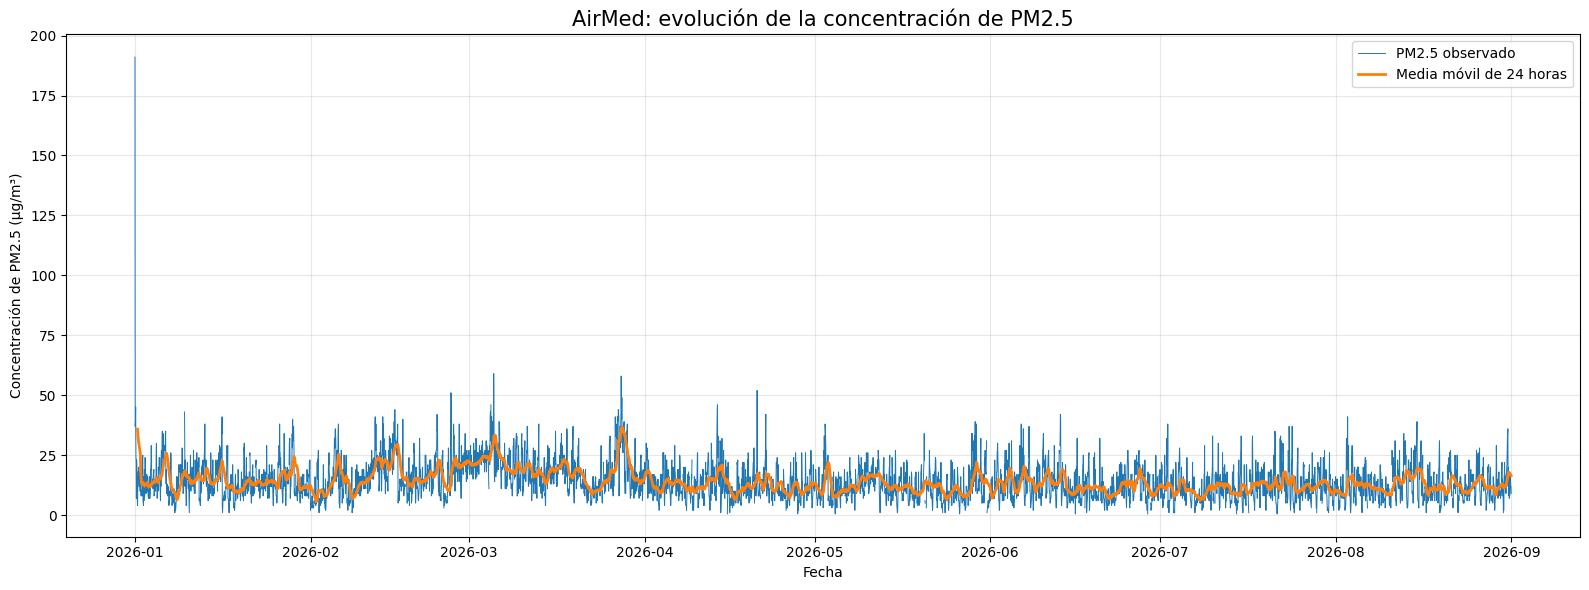

In [5]:
# ============================================================
# AIRMED
# PASO 4.2: EVOLUCIÓN TEMPORAL DE PM2.5
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# Crear una copia para el análisis
df_eda = df.copy()

# Ordenar los registros cronológicamente
df_eda = df_eda.sort_values("timestamp").reset_index(drop=True)

# Configurar la figura
plt.figure(figsize=(16, 6))

# Graficar las mediciones originales
plt.plot(
    df_eda["timestamp"],
    df_eda["pm25_ug_m3"],
    linewidth=0.7,
    label="PM2.5 observado"
)

# Calcular una media móvil de 24 horas
df_eda["pm25_media_24h"] = (
    df_eda["pm25_ug_m3"]
    .rolling(window=24, min_periods=12)
    .mean()
)

# Graficar la tendencia suavizada
plt.plot(
    df_eda["timestamp"],
    df_eda["pm25_media_24h"],
    linewidth=2,
    label="Media móvil de 24 horas"
)

# Configurar título y ejes
plt.title(
    "AirMed: evolución de la concentración de PM2.5",
    fontsize=15
)

plt.xlabel("Fecha")
plt.ylabel("Concentración de PM2.5 (µg/m³)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# ============================================================
# AIRMED
# PASO 4.3: INVESTIGACIÓN DE VALORES EXTREMOS
# ============================================================

# Seleccionar las cinco concentraciones más elevadas
valores_extremos = (
    df_eda.loc[
        df_eda["pm25_ug_m3"].notna(),
        ["timestamp", "pm25_ug_m3"]
    ]
    .nlargest(5, "pm25_ug_m3")
    .sort_values("timestamp")
)

print("Cinco concentraciones más elevadas de PM2.5:")

display(valores_extremos)

Cinco concentraciones más elevadas de PM2.5:


,timestamp,pm25_ug_m3
0,2026-01-01 00:00:00,191.0
1339,2026-02-25 19:00:00,51.0
1520,2026-03-05 08:00:00,59.0
2060,2026-03-27 20:00:00,58.0
2636,2026-04-20 20:00:00,52.0


MEDICIONES ALREDEDOR DEL VALOR EXTREMO


,timestamp,pm25_ug_m3
0,2026-01-01 00:00:00,191.0
1,2026-01-01 01:00:00,37.0
2,2026-01-01 02:00:00,39.0
3,2026-01-01 03:00:00,45.0
4,2026-01-01 04:00:00,25.0
5,2026-01-01 05:00:00,22.0
6,2026-01-01 06:00:00,7.0
7,2026-01-01 07:00:00,23.0
8,2026-01-01 08:00:00,20.0
9,2026-01-01 09:00:00,11.0


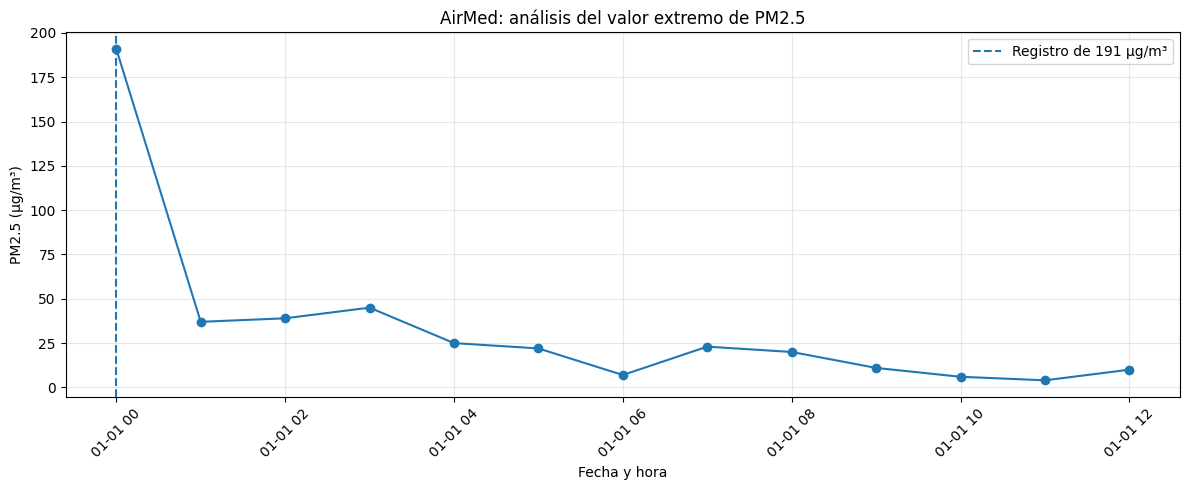

In [7]:
# ============================================================
# AIRMED
# PASO 4.5: INVESTIGACIÓN DEL VALOR EXTREMO
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# Fecha del valor extremo identificado
fecha_extremo = pd.Timestamp("2026-01-01 00:00:00")

# Seleccionar las 12 horas anteriores y posteriores
inicio = fecha_extremo - pd.Timedelta(hours=12)
fin = fecha_extremo + pd.Timedelta(hours=12)

datos_cercanos = (
    df_eda.loc[
        df_eda["timestamp"].between(inicio, fin),
        ["timestamp", "pm25_ug_m3"]
    ]
    .sort_values("timestamp")
)

print("MEDICIONES ALREDEDOR DEL VALOR EXTREMO")
display(datos_cercanos)

# Graficar las concentraciones de ese período
plt.figure(figsize=(12, 5))

plt.plot(
    datos_cercanos["timestamp"],
    datos_cercanos["pm25_ug_m3"],
    marker="o",
    linewidth=1.5
)

plt.axvline(
    fecha_extremo,
    linestyle="--",
    label="Registro de 191 µg/m³"
)

plt.title("AirMed: análisis del valor extremo de PM2.5")
plt.xlabel("Fecha y hora")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

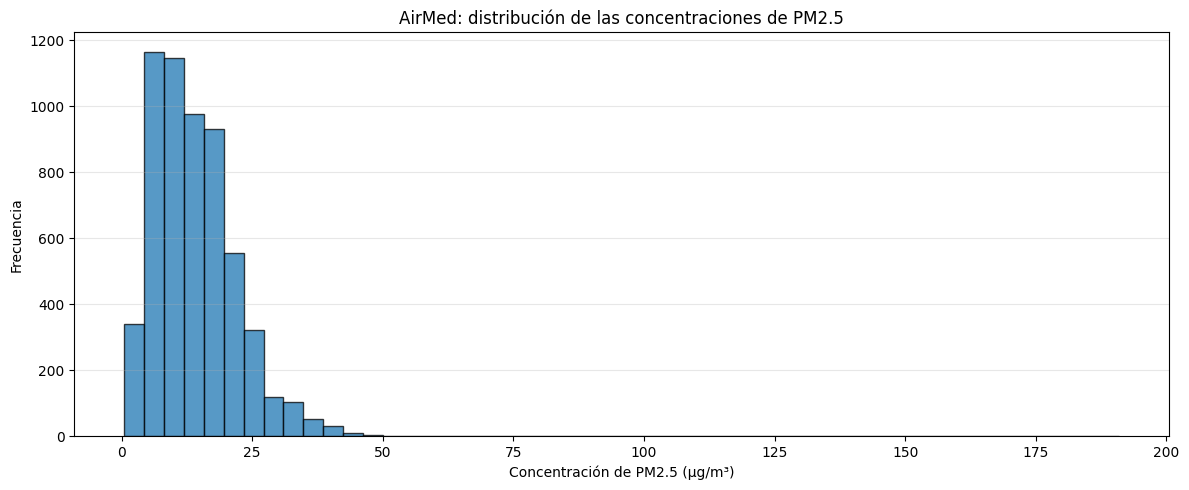

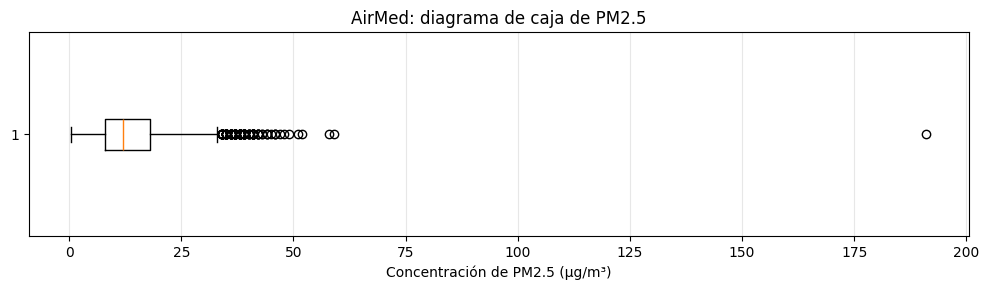

PERCENTILES DE PM2.5


,PM2.5 (µg/m³)
0.25,8.0
0.50,12.0
0.75,18.0
0.90,24.0
0.95,28.0
0.99,38.0


In [8]:
# ============================================================
# AIRMED
# PASO 4.6: DISTRIBUCIÓN DE PM2.5
# ============================================================

# Obtener las mediciones disponibles
pm25 = df_eda["pm25_ug_m3"].dropna()

# Crear un histograma
plt.figure(figsize=(12, 5))

plt.hist(
    pm25,
    bins=50,
    edgecolor="black",
    alpha=0.75
)

plt.title("AirMed: distribución de las concentraciones de PM2.5")
plt.xlabel("Concentración de PM2.5 (µg/m³)")
plt.ylabel("Frecuencia")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Crear un diagrama de caja
plt.figure(figsize=(10, 3))

plt.boxplot(
    pm25,
    vert=False
)

plt.title("AirMed: diagrama de caja de PM2.5")
plt.xlabel("Concentración de PM2.5 (µg/m³)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# Calcular percentiles
print("PERCENTILES DE PM2.5")

percentiles = pm25.quantile(
    [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

display(
    percentiles.rename("PM2.5 (µg/m³)").to_frame()
)

ESTADISTICAS DE PM2.5 POR HORA DEL DIA


,media,mediana,registros
hora,,,
0,13.72,12.0,240
1,12.76,11.0,242
2,13.27,12.0,241
3,13.07,12.0,243
4,14.44,14.0,241
5,16.56,17.0,241
6,19.41,19.0,241
7,19.52,19.0,242
8,18.75,17.0,240


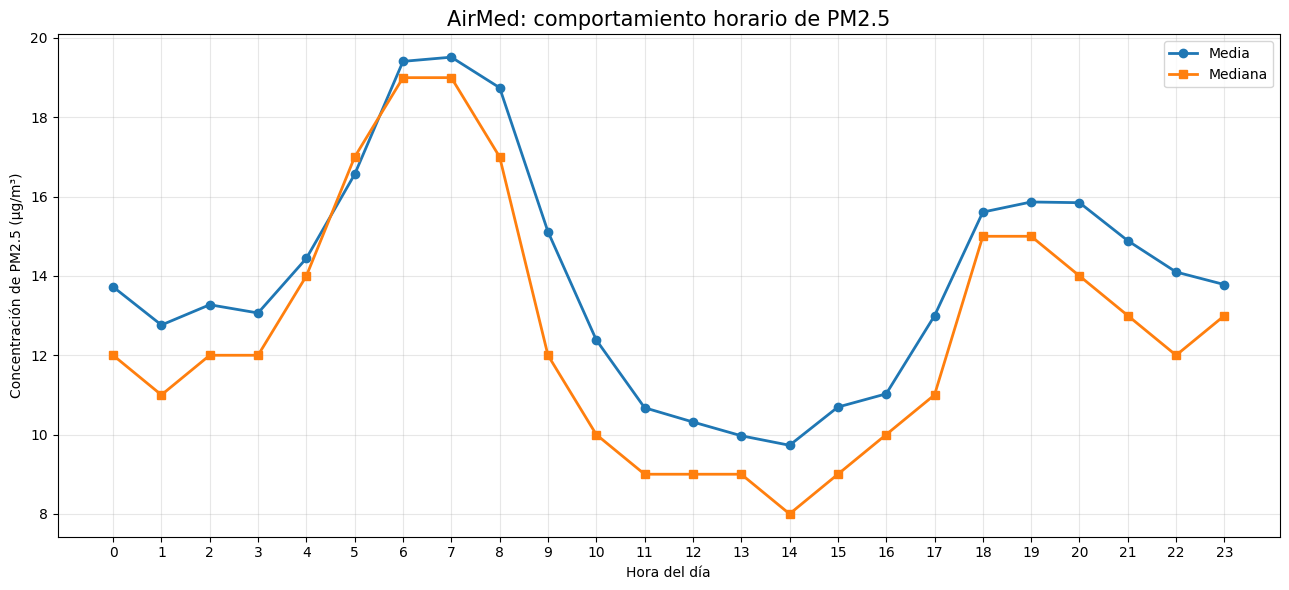

In [9]:
# ============================================================
# AIRMED
# PASO 4.8: ANALISIS DE LOS PATRONES HORARIOS DE PM2.5
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# Crear una copia de los registros con PM2.5 disponible
df_horario = df_eda.dropna(subset=["pm25_ug_m3"]).copy()

# Extraer la hora de cada medición
df_horario["hora"] = df_horario["timestamp"].dt.hour

# Calcular estadísticas por hora del día
perfil_horario = (
    df_horario
    .groupby("hora")["pm25_ug_m3"]
    .agg(
        media="mean",
        mediana="median",
        registros="count"
    )
    .reindex(range(24))
)

# Mostrar los resultados
print("ESTADISTICAS DE PM2.5 POR HORA DEL DIA")

display(perfil_horario.round(2))

# ------------------------------------------------------------
# Grafica comparativa de la media y la mediana
# ------------------------------------------------------------

plt.figure(figsize=(13, 6))

plt.plot(
    perfil_horario.index,
    perfil_horario["media"],
    marker="o",
    linewidth=2,
    label="Media"
)

plt.plot(
    perfil_horario.index,
    perfil_horario["mediana"],
    marker="s",
    linewidth=2,
    label="Mediana"
)

plt.title(
    "AirMed: comportamiento horario de PM2.5",
    fontsize=15
)

plt.xlabel("Hora del día")
plt.ylabel("Concentración de PM2.5 (µg/m³)")

plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

ESTADISTICAS DE PM2.5 POR DIA DE LA SEMANA


,media,mediana,registros
dia_semana,,,
Lunes,13.69,12.0,836
Martes,13.51,12.0,800
Miércoles,14.19,12.0,803
Jueves,14.81,13.0,832
Viernes,14.35,12.0,831
Sábado,14.40,13.0,829
Domingo,12.72,11.0,833


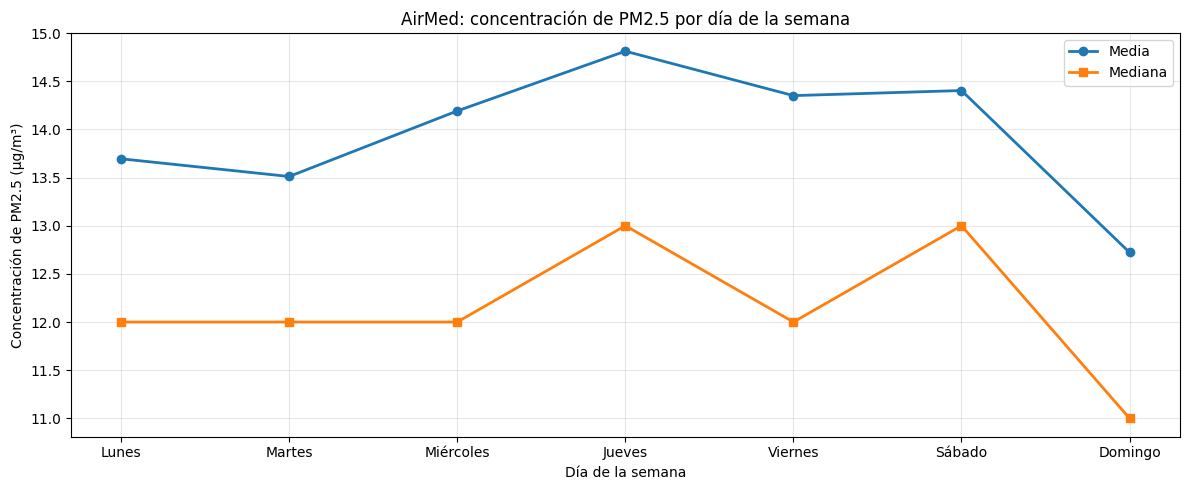

In [10]:
# ============================================================
# AIRMED
# PASO 4.10: ANALISIS POR DIA DE LA SEMANA
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# Crear un conjunto de datos para este análisis.
# No modificamos el dataset original.
df_dias = df_eda.dropna(subset=["pm25_ug_m3"]).copy()

# Orden de los días: lunes = 0, domingo = 6
orden_dias = [
    "Lunes",
    "Martes",
    "Miércoles",
    "Jueves",
    "Viernes",
    "Sábado",
    "Domingo"
]

# Obtener el número y el nombre del día de la semana
df_dias["numero_dia"] = df_dias["timestamp"].dt.dayofweek

df_dias["dia_semana"] = df_dias["numero_dia"].map({
    0: "Lunes",
    1: "Martes",
    2: "Miércoles",
    3: "Jueves",
    4: "Viernes",
    5: "Sábado",
    6: "Domingo"
})

# Convertir el día en una categoría ordenada
df_dias["dia_semana"] = pd.Categorical(
    df_dias["dia_semana"],
    categories=orden_dias,
    ordered=True
)

# Calcular estadísticas por día
resumen_dias = (
    df_dias
    .groupby("dia_semana", observed=False)["pm25_ug_m3"]
    .agg(
        media="mean",
        mediana="median",
        registros="count"
    )
)

print("ESTADISTICAS DE PM2.5 POR DIA DE LA SEMANA")

display(resumen_dias.round(2))

# ============================================================
# GRAFICA COMPARATIVA
# ============================================================

plt.figure(figsize=(12, 5))

plt.plot(
    orden_dias,
    resumen_dias["media"],
    marker="o",
    linewidth=2,
    label="Media"
)

plt.plot(
    orden_dias,
    resumen_dias["mediana"],
    marker="s",
    linewidth=2,
    label="Mediana"
)

plt.title(
    "AirMed: concentración de PM2.5 por día de la semana"
)

plt.xlabel("Día de la semana")
plt.ylabel("Concentración de PM2.5 (µg/m³)")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

PM2.5: DIAS LABORABLES VS. FINES DE SEMANA


,media,mediana,desviacion_estandar,registros
tipo_dia,,,,
Día laborable,14.12,12.0,8.33,4102
Fin de semana,13.56,12.0,7.18,1662


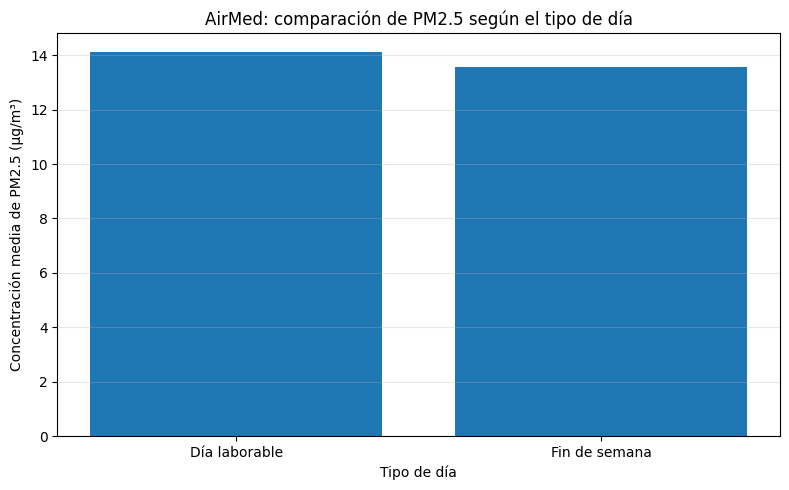

In [11]:
# ============================================================
# AIRMED
# COMPARACION ENTRE DIAS LABORABLES Y FINES DE SEMANA
# ============================================================

# Clasificar las observaciones según el tipo de día
df_dias["tipo_dia"] = df_dias["numero_dia"].apply(
    lambda dia: (
        "Fin de semana" if dia >= 5
        else "Día laborable"
    )
)

# Calcular estadísticas para cada grupo
resumen_tipo_dia = (
    df_dias
    .groupby("tipo_dia")["pm25_ug_m3"]
    .agg(
        media="mean",
        mediana="median",
        desviacion_estandar="std",
        registros="count"
    )
)

print("PM2.5: DIAS LABORABLES VS. FINES DE SEMANA")

display(resumen_tipo_dia.round(2))

# Graficar las medias
plt.figure(figsize=(8, 5))

plt.bar(
    resumen_tipo_dia.index,
    resumen_tipo_dia["media"]
)

plt.title(
    "AirMed: comparación de PM2.5 según el tipo de día"
)

plt.xlabel("Tipo de día")
plt.ylabel("Concentración media de PM2.5 (µg/m³)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

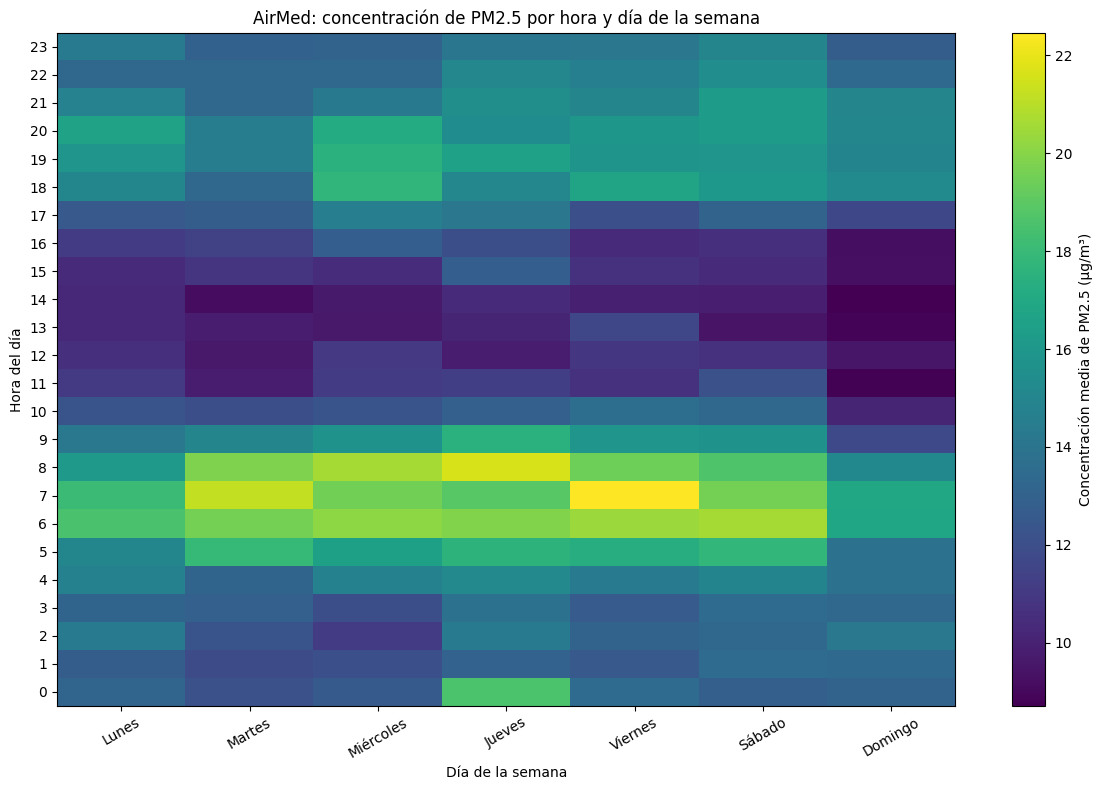

In [12]:
# ============================================================
# AIRMED
# MAPA DE CALOR: HORA VS. DIA DE LA SEMANA
# ============================================================

# Extraer la hora de cada observación
df_dias["hora"] = df_dias["timestamp"].dt.hour

# Calcular la concentración media para cada combinación
mapa_pm25 = df_dias.pivot_table(
    index="hora",
    columns="dia_semana",
    values="pm25_ug_m3",
    aggfunc="mean",
    observed=False
)

# Mantener el orden correcto de los días
mapa_pm25 = mapa_pm25.reindex(columns=orden_dias)

# Dibujar el mapa de calor
plt.figure(figsize=(12, 8))

imagen = plt.imshow(
    mapa_pm25,
    aspect="auto",
    origin="lower",
    interpolation="nearest"
)

plt.colorbar(
    imagen,
    label="Concentración media de PM2.5 (µg/m³)"
)

plt.xticks(
    range(len(orden_dias)),
    orden_dias,
    rotation=30
)

plt.yticks(range(24), range(24))

plt.title(
    "AirMed: concentración de PM2.5 por hora y día de la semana"
)

plt.xlabel("Día de la semana")
plt.ylabel("Hora del día")

plt.tight_layout()
plt.show()

In [13]:
# ============================================================
# AIRMED
# PASO 4.12: AUDITORIA DE CONTINUIDAD TEMPORAL
# ============================================================

import pandas as pd

# Crear una copia con las columnas necesarias
df_auditoria = (
    df[["timestamp", "pm25_ug_m3"]]
    .copy()
    .sort_values("timestamp")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 1. Verificar los intervalos entre mediciones
# ------------------------------------------------------------

df_auditoria["intervalo"] = (
    df_auditoria["timestamp"].diff()
)

print("INTERVALOS ENTRE MARCAS DE TIEMPO")
display(
    df_auditoria["intervalo"]
    .value_counts()
    .sort_index()
    .rename_axis("Intervalo")
    .reset_index(name="Cantidad")
)

# Identificar intervalos mayores a una hora
gaps = df_auditoria.loc[
    df_auditoria["intervalo"] > pd.Timedelta(hours=1),
    ["timestamp", "intervalo"]
]

print("\nINTERVALOS MAYORES A UNA HORA")
print(f"Cantidad de intervalos: {len(gaps)}")

if len(gaps) > 0:
    display(gaps.head(20))
else:
    print("No se encontraron intervalos mayores a una hora.")

# ------------------------------------------------------------
# 2. Identificar secuencias consecutivas de valores faltantes
# ------------------------------------------------------------

df_auditoria["faltante_pm25"] = (
    df_auditoria["pm25_ug_m3"].isna()
)

# Identificar cuándo cambia el estado de faltante a disponible
# o de disponible a faltante
df_auditoria["grupo"] = (
    df_auditoria["faltante_pm25"]
    .ne(df_auditoria["faltante_pm25"].shift())
    .cumsum()
)

# Conservar solamente las filas con PM2.5 faltante
df_faltantes = df_auditoria[
    df_auditoria["faltante_pm25"]
].copy()

# Resumir cada secuencia consecutiva de valores faltantes
if not df_faltantes.empty:

    secuencias_faltantes = (
        df_faltantes
        .groupby("grupo")
        .agg(
            inicio=("timestamp", "min"),
            fin=("timestamp", "max"),
            cantidad=("timestamp", "size")
        )
        .reset_index(drop=True)
    )

    print("\nSECUENCIAS DE VALORES FALTANTES DE PM2.5")
    print(
        "Cantidad de secuencias consecutivas:",
        len(secuencias_faltantes)
    )

    print(
        "Mayor cantidad de horas consecutivas sin PM2.5:",
        secuencias_faltantes["cantidad"].max()
    )

    display(
        secuencias_faltantes.sort_values(
            "cantidad",
            ascending=False
        ).head(20)
    )

else:
    print("\nNo se encontraron valores faltantes de PM2.5.")

# ------------------------------------------------------------
# 3. Verificar la cantidad total de registros
# ------------------------------------------------------------

print("\nRESUMEN DE LA AUDITORÍA")
print(f"Total de registros: {len(df_auditoria)}")
print(
    "Valores disponibles de PM2.5:",
    df_auditoria["pm25_ug_m3"].notna().sum()
)
print(
    "Valores faltantes de PM2.5:",
    df_auditoria["pm25_ug_m3"].isna().sum()
)

INTERVALOS ENTRE MARCAS DE TIEMPO


,Intervalo,Cantidad
0,0 days 01:00:00,5831



INTERVALOS MAYORES A UNA HORA
Cantidad de intervalos: 0
No se encontraron intervalos mayores a una hora.

SECUENCIAS DE VALORES FALTANTES DE PM2.5
Cantidad de secuencias consecutivas: 56
Mayor cantidad de horas consecutivas sin PM2.5: 3


,inicio,fin,cantidad
22,2026-04-25 00:00:00,2026-04-25 02:00:00,3
45,2026-07-16 16:00:00,2026-07-16 18:00:00,3
16,2026-03-24 14:00:00,2026-03-24 15:00:00,2
9,2026-01-31 11:00:00,2026-01-31 12:00:00,2
28,2026-05-20 15:00:00,2026-05-20 16:00:00,2
29,2026-05-23 15:00:00,2026-05-23 16:00:00,2
24,2026-04-28 07:00:00,2026-04-28 08:00:00,2
36,2026-06-28 17:00:00,2026-06-28 18:00:00,2
39,2026-07-10 12:00:00,2026-07-10 13:00:00,2
53,2026-08-18 12:00:00,2026-08-18 13:00:00,2



RESUMEN DE LA AUDITORÍA
Total de registros: 5832
Valores disponibles de PM2.5: 5764
Valores faltantes de PM2.5: 68


## 5. Conclusiones del análisis exploratorio

### 5.1. Características del conjunto de datos

Se analizaron 5.832 registros horarios de la estación MED-PBLQ,
correspondientes al período comprendido entre el 1 de enero
y el 31 de agosto de 2026.

La variable principal del proyecto es la concentración de
material particulado PM2.5, medida en µg/m³.

Se encontraron 68 mediciones faltantes de PM2.5, equivalentes
al 1,17 % del total. No se identificaron marcas de tiempo
duplicadas ni intervalos superiores a una hora.

### 5.2. Distribución de PM2.5

La concentración media observada fue de aproximadamente
13,96 µg/m³ y la mediana fue de 12 µg/m³.

La distribución presenta asimetría hacia la derecha, con
un número reducido de concentraciones elevadas.

Se identificó un valor máximo de 191 µg/m³, que deberá
investigarse antes de establecer conclusiones sobre su validez.

### 5.3. Patrones temporales

El análisis horario mostró concentraciones medias relativamente
elevadas durante las primeras horas de la mañana, especialmente
a las 6:00 y 7:00, y valores inferiores alrededor del mediodía
y las primeras horas de la tarde.

También se observaron diferencias entre los días de la semana.
La concentración media fue de 14,12 µg/m³ durante los días
laborables y de 13,56 µg/m³ durante los fines de semana.

Estos resultados son descriptivos y no demuestran por sí solos
las causas de las variaciones observadas.

### 5.4. Decisiones para el modelado

Los resultados justifican explorar modelos de redes neuronales
recurrentes para aprender patrones temporales de PM2.5.

Se comenzará con una arquitectura univariada que utilizará
mediciones históricas de PM2.5 para predecir concentraciones
futuras.

Los valores faltantes y las observaciones extremas recibirán
un tratamiento documentado durante el preprocesamiento.

### 5.5. Limitaciones

El período de ocho meses es limitado para estudiar patrones
estacionales entre diferentes años.

Además, los patrones observados corresponden a una estación
de monitoreo y no deben generalizarse automáticamente a todo
Medellín o al Valle de Aburrá.

La capacidad predictiva de los modelos deberá comprobarse
mediante una evaluación temporal independiente.